In [8]:
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
import pandas as pd
from sklearn.model_selection import train_test_split


insurance_data=pd.read_csv("insurance.csv")
X=insurance_data.drop(columns=["charges"])
y=insurance_data["charges"]
X=pd.get_dummies(X,columns=["region"],drop_first=True,dtype=int)
X["sex"]=X["sex"].map({"female":1,"male":0})
X["smoker"]=X["smoker"].map({"yes":1,"no":0})
X["age_smoker"]=X["age"]*X["smoker"]
X["bmi_smoker"]=X["bmi"]*X["smoker"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


20922599.871035974
20921803.698431384
20914832.635089148
20908106.77995453
20890881.000633504
20872844.794796687
20877828.53237883
20937537.133939773
21046489.293890774
21196929.869608894
22423172.68602322


<Axes: >

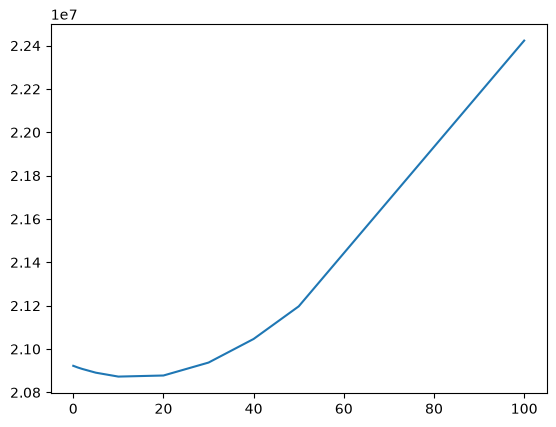

In [16]:
from sklearn.metrics import r2_score
import seaborn as sns
alphas=[0.001,0.1,1,2,5,10,20,30,40,50,100]
mses=[]
for a in alphas:
    model=linear_model.Lasso(alpha=a)
    model.fit(X_train,y_train)
    y_pred=model.predict(X_test)
    mse=mean_squared_error(y_test, y_pred)
    mses.append(mse)
    print(mse)

sns.lineplot(x=alphas,y=mses)

In [21]:
# Lasso cv / Ridge CV
from sklearn.linear_model import LassoCV
from sklearn.metrics import r2_score
a=[0.001,0.1,1,2,5,10,20,30,40,50,100]

lasso_cv_model=LassoCV(alphas=a,cv=5, random_state=42, max_iter=1000)
lasso_cv_model.fit(X_train,y_train)
print(lasso_cv_model.alpha_)

y_pred=lasso_cv_model.predict(X_test)
mse=mean_squared_error(y_test, y_pred)
print(mse)

# r2 square
r2=r2_score(y_test,y_pred)
print(r2)

0.001
20922599.871035974
0.8652317499151698
